# Logistic Regression / Ibm Hr Analytic Employee Attrition & Performance / Knn / Knnclassifier

**Type:** Guided machine-learning practice notebook (course-based study).  
**Purpose:** Explore the dataset and the modeling/preprocessing operations illustrated in the code below.  
**Data in this folder:** `12-health_risk_classification.csv`.  
**Methods referenced:** `KNeighborsClassifier`.

> **Reproducibility note:** Run cells sequentially from this notebook’s folder. Outputs are historical study results, not independently validated benchmarks. The data files were supplied with the original archive; see `DATA_SOURCES.md` at the repository root for provenance checks.


In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("12-health_risk_classification.csv")

In [3]:
df

,bmi_score,blood_pressure_variation,activity_level_index,high_risk_flag
0,0.564223,0.652825,1.262925,1
1,-1.692569,2.981229,-0.180331,1
2,0.770383,0.400475,1.365806,1
3,2.135007,0.150832,3.084596,0
4,0.360342,1.026132,1.251574,1
...,...,...,...,...
995,0.640158,-1.962795,-0.541917,0
996,-2.784745,2.717867,-1.894291,1
997,0.238598,0.840739,0.946540,1
998,-1.044982,-0.055455,-1.496340,1


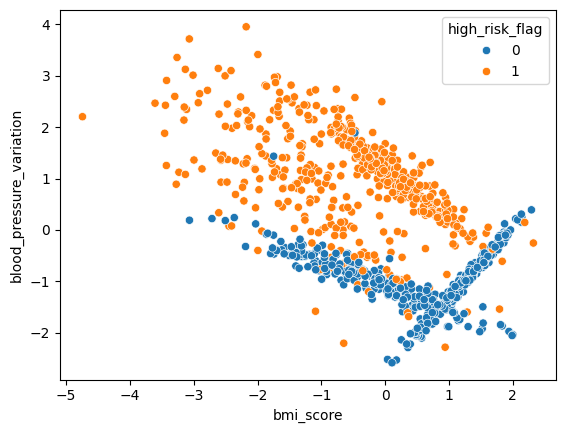

In [4]:
sns.scatterplot(x = df["bmi_score"], y = df["blood_pressure_variation"], hue = df["high_risk_flag"])
plt.show()

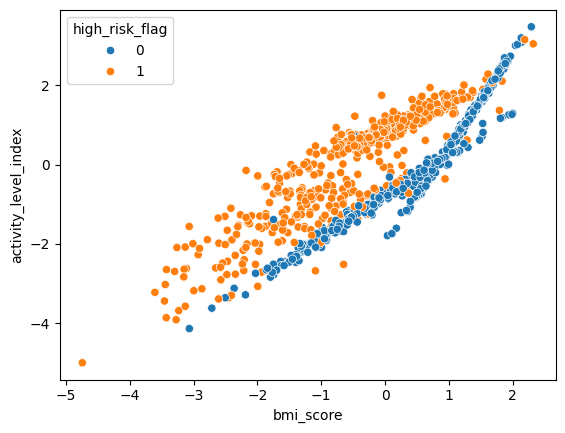

In [5]:
sns.scatterplot(x = df["bmi_score"], y = df["activity_level_index"], hue = df["high_risk_flag"])
plt.show()

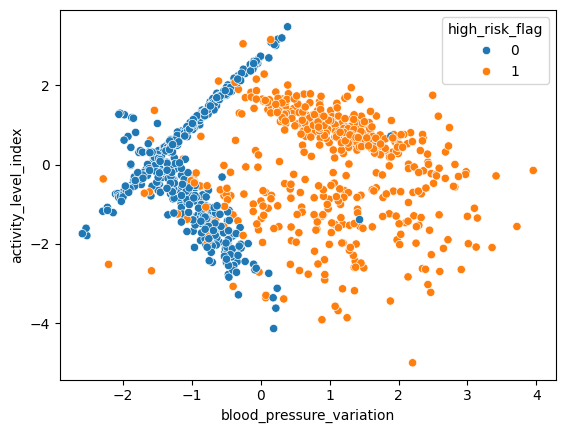

In [6]:
sns.scatterplot(x = df["blood_pressure_variation"], y = df["activity_level_index"], hue = df["high_risk_flag"])
plt.show()

In [7]:
from sklearn.model_selection import train_test_split

In [8]:
X = df.drop("high_risk_flag", axis = 1)
y = df["high_risk_flag"]

In [9]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)

In [10]:
from sklearn.neighbors import KNeighborsClassifier

In [11]:
from sklearn.model_selection import GridSearchCV

In [12]:
n_neighbors = [3, 4, 5]
weights = ["disance", "uniform"]
algorithm = ["auto", "kd_tree", "ball_tree", "brute"]

params = dict(n_neighbors = n_neighbors, weights = weights,algorithm = algorithm)

In [13]:
knc = KNeighborsClassifier()

In [14]:
knc.fit(X_train, y_train)

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [15]:
y_pred = knc.predict(X_test)

In [16]:
from sklearn.metrics import classification_report, confusion_matrix

In [17]:
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

[[103   0]
 [  9  88]]
              precision    recall  f1-score   support

           0       0.92      1.00      0.96       103
           1       1.00      0.91      0.95        97

    accuracy                           0.95       200
   macro avg       0.96      0.95      0.95       200
weighted avg       0.96      0.95      0.95       200



In [18]:
grid = GridSearchCV(estimator = knc, param_grid = params)

In [19]:
import warnings
warnings.filterwarnings("ignore")

In [20]:
grid.fit(X_train, y_train)

,estimator,KNeighborsClassifier()
,param_grid,"{'algorithm': ['auto', 'kd_tree', ...], 'n_neighbors': [3, 4, ...], 'weights': ['disance', 'uniform']}"
,scoring,None
,n_jobs,None
,refit,True
,cv,None
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,n_neighbors,4


In [21]:
grid.best_params_

{'algorithm': 'auto', 'n_neighbors': 4, 'weights': 'uniform'}

In [22]:
y_pred = grid.predict(X_test)

In [23]:
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

[[103   0]
 [  9  88]]
              precision    recall  f1-score   support

           0       0.92      1.00      0.96       103
           1       1.00      0.91      0.95        97

    accuracy                           0.95       200
   macro avg       0.96      0.95      0.95       200
weighted avg       0.96      0.95      0.95       200

